# 02 · Análisis exploratorio de datos (EDA)

**Proyecto semestral IMT2200, Grupo 6:** *¿Mide el NEM lo mismo para todos?*

**Entrada:** `data/processed/panel_completo.parquet` (generado por
`01_carga_y_limpieza.ipynb`). **Salidas:** `data/processed/muestra.parquet` (para el
modelamiento) y las figuras en `imgs/`.

El EDA está ordenado según las tres preguntas guía de la propuesta, precedidas por
secciones de preparación que responden a la retroalimentación de la Entrega 1:

| Sección | Contenido |
|---|---|
| 0 | Configuración y carga del panel |
| 1 | Calidad de datos y comparabilidad entre años |
| 2 | Muestra analítica y definición de la brecha |
| 3 | Sensibilidad a la prueba PAES elegida |
| 4 | Pregunta 1: ¿cómo se relacionan NEM y PAES? |
| 5 | Pregunta 2: brecha según dependencia y nivel socioeconómico |
| 6 | Nivel establecimiento (insumo para el modelo jerárquico) |
| 7 | Pregunta 3: brecha y etapas del acceso |
| 8 | Evolución 2023-2026 |
| 9 | Síntesis de hallazgos |

Las celdas con **VERIFICAR** en los comentarios dependen de un supuesto que hay que
confirmar mirando su salida.

## 0. Configuración

In [1]:
# 0. Rutas, librerías, módulos del proyecto (src/) y carga del panel.
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Raíz del proyecto (funciona si el notebook se abre desde notebooks/ o
# desde la raíz) para poder importar los módulos de src/.
RAIZ = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(RAIZ))

# Los módulos de src/ se importan después de agregar la raíz al path; por
# eso llevan "noqa: E402" (PEP8 pide los imports al inicio del archivo).
from src.config import (ARCHIVO_MUESTRA, ARCHIVO_PANEL,  # noqa: E402
                        CRITERIO_RENDICION, DEPENDENCIA_ETIQUETAS, DIR_IMGS,
                        ELECTIVAS, ESTADOS_SELECCION, ESTADOS_VALIDOS,
                        INCLUIR_AMBAS, MIN_ESTUDIANTES_COLEGIO, MIN_N_CELDA,
                        ORDEN_DEPENDENCIA, PRUEBAS_PAES,
                        RBD_SIN_ESTABLECIMIENTO)
from src.estadistica import (correlaciones_anio,  # noqa: E402
                             diagnostico_columnas, proporcion_varianza_entre,
                             resumen, tasas_acceso, v_de_cramer)
from src.graficos import (aplicar_estilo, graficar_medias,  # noqa: E402
                          mostrar)
from src.muestra import (agregar_variables, calcular_brechas,  # noqa: E402
                         construir_muestra, puntaje_valido)

aplicar_estilo()
panel_completo = pd.read_parquet(ARCHIVO_PANEL)
print(f'Panel cargado: {len(panel_completo)} filas, '
      f'{panel_completo.shape[1]} columnas, '
      f'años {sorted(panel_completo["ANIO"].unique().tolist())}')

Panel cargado: 1240008 filas, 37 columnas, años [2023, 2024, 2025, 2026]


## 1 Calidad de datos y comparabilidad entre años

Antes de mirar la brecha se revisa que las variables signifiquen lo mismo en los
cuatro procesos (punto pedido explícitamente en la retroalimentación): tipos de
datos, faltantes, ceros usados como "no rindió", rangos de puntaje y códigos de
las variables categóricas.

In [2]:
# 1.a Tipos de datos de las columnas clave (deberían ser todas numéricas
# después de la Decisión 4, salvo RAMA_EDUCACIONAL).
COLUMNAS_DIAGNOSTICO: list[str] = [
    'ANYO_DE_EGRESO', 'PROMEDIO_NOTAS', 'PTJE_NEM', 'CLEC_REG_ACTUAL',
    'MATE1_REG_ACTUAL', 'HCSOC_REG_ACTUAL', 'CIEN_REG_ACTUAL', 'RBD',
    'DEPENDENCIA', 'RAMA_EDUCACIONAL', 'INGRESO_PERCAPITA_GRUPO_FA',
]
print('Tipos de datos en panel_completo:')
print(panel_completo[COLUMNAS_DIAGNOSTICO].dtypes.to_string())

Tipos de datos en panel_completo:
ANYO_DE_EGRESO                float64
PROMEDIO_NOTAS                float64
PTJE_NEM                        int64
CLEC_REG_ACTUAL               float64
MATE1_REG_ACTUAL              float64
HCSOC_REG_ACTUAL              float64
CIEN_REG_ACTUAL               float64
RBD                           float64
DEPENDENCIA                   float64
RAMA_EDUCACIONAL                  str
INGRESO_PERCAPITA_GRUPO_FA    float64


In [3]:
# 1.b Porcentaje de nulos, de ceros y rango (mín-máx) por año.
# Un % de ceros alto en un puntaje indica que 0 codifica "no rindió".
diag = diagnostico_columnas(panel_completo, COLUMNAS_DIAGNOSTICO)
for medida in ['pct_nulo', 'pct_cero', 'min', 'max']:
    print(f'\n--- {medida} (filas: columna, columnas: año) ---')
    display(diag.pivot(index='columna', columns='ANIO', values=medida)
            .round(1))


--- pct_nulo (filas: columna, columnas: año) ---


ANIO,2023,2024,2025,2026
columna,,,,
ANYO_DE_EGRESO,0.1,0.1,0.0,0.1
CIEN_REG_ACTUAL,7.3,7.0,6.3,6.1
CLEC_REG_ACTUAL,7.3,7.0,6.3,6.1
DEPENDENCIA,0.9,1.6,1.6,1.0
HCSOC_REG_ACTUAL,7.3,7.0,6.3,6.1
INGRESO_PERCAPITA_GRUPO_FA,24.6,25.7,27.2,27.6
MATE1_REG_ACTUAL,7.3,7.0,6.3,6.1
PROMEDIO_NOTAS,0.0,0.0,0.0,0.0
PTJE_NEM,0.0,0.0,0.0,0.0



--- pct_cero (filas: columna, columnas: año) ---


ANIO,2023,2024,2025,2026
columna,,,,
ANYO_DE_EGRESO,0.0,0.0,0.0,0.0
CIEN_REG_ACTUAL,38.8,38.2,37.5,39.3
CLEC_REG_ACTUAL,12.9,13.7,14.0,15.5
DEPENDENCIA,0.0,0.0,0.0,0.0
HCSOC_REG_ACTUAL,50.5,50.2,51.5,54.0
INGRESO_PERCAPITA_GRUPO_FA,0.0,0.0,0.0,0.0
MATE1_REG_ACTUAL,13.3,14.3,15.6,17.1
PROMEDIO_NOTAS,1.5,1.7,1.7,1.9
PTJE_NEM,1.5,1.7,1.7,1.9



--- min (filas: columna, columnas: año) ---


ANIO,2023,2024,2025,2026
columna,,,,
ANYO_DE_EGRESO,1961.0,0.0,0.0,0.0
CIEN_REG_ACTUAL,0.0,0.0,0.0,0.0
CLEC_REG_ACTUAL,0.0,0.0,0.0,0.0
DEPENDENCIA,1.0,1.0,1.0,1.0
HCSOC_REG_ACTUAL,0.0,0.0,0.0,0.0
INGRESO_PERCAPITA_GRUPO_FA,1.0,1.0,1.0,1.0
MATE1_REG_ACTUAL,0.0,0.0,0.0,0.0
PROMEDIO_NOTAS,0.0,0.0,0.0,0.0
PTJE_NEM,0.0,0.0,0.0,0.0



--- max (filas: columna, columnas: año) ---


ANIO,2023,2024,2025,2026
columna,,,,
ANYO_DE_EGRESO,2022.0,2023.0,2024.0,2025.0
CIEN_REG_ACTUAL,1000.0,1000.0,1000.0,1000.0
CLEC_REG_ACTUAL,1000.0,1000.0,1000.0,1000.0
DEPENDENCIA,6.0,6.0,6.0,6.0
HCSOC_REG_ACTUAL,1000.0,1000.0,1000.0,1000.0
INGRESO_PERCAPITA_GRUPO_FA,10.0,10.0,10.0,10.0
MATE1_REG_ACTUAL,1000.0,1000.0,1000.0,1000.0
PROMEDIO_NOTAS,7.0,7.0,7.0,7.0
PTJE_NEM,1000.0,1000.0,1000.0,1000.0


In [4]:
# 1.c Códigos presentes en las variables categóricas, por año.
# VERIFICAR: que los códigos sean los mismos en los 4 procesos y que todos
# los de DEPENDENCIA estén en DEPENDENCIA_ETIQUETAS.
for col in ['DEPENDENCIA', 'RAMA_EDUCACIONAL', 'INGRESO_PERCAPITA_GRUPO_FA']:
    print(f'\n--- {col} (conteo por año; <NA> = faltante) ---')
    display(pd.crosstab(panel_completo[col].astype('string').fillna('<NA>'),
                        panel_completo['ANIO']))

codigos = set(panel_completo['DEPENDENCIA'].dropna().astype(int).unique())
sin_mapa = codigos - set(DEPENDENCIA_ETIQUETAS)
print(f'Códigos de DEPENDENCIA sin etiqueta: {sorted(sin_mapa) or "ninguno"}')


--- DEPENDENCIA (conteo por año; <NA> = faltante) ---


ANIO,2023,2024,2025,2026
DEPENDENCIA,,,,
1.0,28882,28545,27724,19922
2.0,53793,55629,54871,48543
3.0,158468,164257,165980,168231
4.0,31555,32448,33584,35248
5.0,9948,10455,10524,10571
6.0,11508,13084,15974,34372
<NA>,2658,4932,5102,3200



--- RAMA_EDUCACIONAL (conteo por año; <NA> = faltante) ---


ANIO,2023,2024,2025,2026
RAMA_EDUCACIONAL,,,,
,630,2520,0,0
<NA>,0,0,2434,463
H1,200476,206830,211051,216909
H2,18238,17915,17644,17760
H3,1384,1690,1950,1993
H4,644,722,718,744
T1,23755,24274,24274,24819
T2,27698,29809,29929,30721
T3,20316,21707,21725,22147



--- INGRESO_PERCAPITA_GRUPO_FA (conteo por año; <NA> = faltante) ---


ANIO,2023,2024,2025,2026
INGRESO_PERCAPITA_GRUPO_FA,,,,
1.0,52904,50552,44855,44641
10.0,13326,14120,16457,14448
2.0,38540,35740,31232,33590
3.0,24405,24651,22275,23658
4.0,18984,20066,19458,21701
5.0,15097,15044,15383,17318
6.0,12847,17390,17399,15915
7.0,16347,18767,17748,25266
8.0,18238,20005,26287,20715


Códigos de DEPENDENCIA sin etiqueta: ninguno


In [5]:
# 1.d ¿Cuál es la "primera rendición"? Entre egresados recientes, cuántos
# rindieron cada prueba en invierno (INV, junio) y/o regular (REG, diciembre)
# del proceso actual, y cuántos tienen rendiciones del proceso anterior.
# VERIFICAR: si muchos rindieron INV y REG, la decisión de usar REG como
# "primera" debe justificarse (ver CRITERIO_RENDICION en 2).
recientes = panel_completo[panel_completo['egresado_reciente']]
filas = []
for prueba in ['CLEC', 'MATE1', 'HCSOC', 'CIEN']:
    reg = puntaje_valido(recientes[f'{prueba}_REG_ACTUAL'])
    inv = puntaje_valido(recientes[f'{prueba}_INV_ACTUAL'])
    ant = (puntaje_valido(recientes[f'{prueba}_REG_ANTERIOR'])
           | puntaje_valido(recientes[f'{prueba}_INV_ANTERIOR']))
    conteo = pd.DataFrame({'solo_REG': reg & ~inv, 'solo_INV': inv & ~reg,
                           'REG_e_INV': reg & inv, 'proceso_anterior': ant})
    tabla = conteo.groupby(recientes['ANIO']).sum()
    tabla.insert(0, 'prueba', PRUEBAS_PAES[prueba])
    filas.append(tabla)
print(f'Egresados recientes: {len(recientes)} (4 años)')
display(pd.concat(filas).reset_index().set_index(['prueba', 'ANIO']))

Egresados recientes: 835424 (4 años)


solo_REG  solo_INV  REG_e_INV  proceso_anterior
prueba                  ANIO                                                 
Comp. Lectora           2023    171953         8         21                49
                        2024    177313         9         16                45
                        2025    181104         0          0                34
                        2026    185231         0          0                51
Matemática 1            2023    169573         0          0                 0
                        2024    174766         8         16                42
                        2025    178235         0          0                30
                        2026    182045         0          0                45
Historia y Cs. Sociales 2023     94832         5          7                30
                        2024    101391         2          5                25
                        2025    101894         0          0                19
                        2026    100082         0          0                29
Ciencias                2023    115875         5         16                19
                        2024    120483         7         11                28
                        2025    126309         0          0                16
                        2026    126637         0          0                27

## 2. Muestra analítica y definición de la brecha

La muestra son los egresados del año inmediatamente anterior al proceso, con NEM
válido, que rindieron **al menos una** electiva y que cursaron **educación regular
(niños y jóvenes) en un establecimiento identificado**: se excluye a quienes
validan o reconocen estudios (H3 y H4, sin RBD), a la educación de adultos
(`CODIGO_ENS` x60 a x63 y 963) y al RBD 99999, porque su NEM no proviene de un
colegio regular comparable. Se forman tres grupos: solo
Ciencias, solo Historia y **Ambas** (PAES electiva = promedio de los dos puntajes).
Cada estudiante se compara solo con su grupo, porque Ciencias e Historia son pruebas
distintas rendidas por poblaciones distintas.

Las brechas se definen una sola vez, en `src/muestra.py`:

- **Brecha condicional (medida principal)**: residuo de una regresión lineal simple
  de `NEM_z` sobre `PAES_z`, ajustada en cada año y grupo de electiva. Es el NEM
  observado menos el NEM esperado dada la PAES (como ambas están en z, el esperado
  es `r·PAES_z`). Responde *"a igual PAES, ¿distinto NEM?"*. `> 0` significa más
  NEM que otros estudiantes con la misma PAES.
- **Brecha simple** `NEM_z - PAES_z`, con z dentro de cada año y grupo de electiva.
  `> 0` significa una posición relativa más alta en NEM que en la PAES. Se mantiene
  solo como comparación (5.f), porque mezcla diferencias reales con regresión a la
  media.

Ambas tienen media 0 en cada año y grupo, así que lo comparable son las
**diferencias entre grupos** (dependencia, decil, colegio), no su nivel entre años.

In [6]:
# 2.a Muestra analítica (filtros definidos en src/muestra.py).
# Parámetros en src/config.py: CRITERIO_RENDICION e INCLUIR_AMBAS.
muestra, embudo = construir_muestra(panel_completo, CRITERIO_RENDICION,
                                    INCLUIR_AMBAS)
print(f'Criterio de rendición: {CRITERIO_RENDICION} | '
      f'incluir ambas electivas: {INCLUIR_AMBAS}')
print('Embudo de filtros (n por año):')
display(embudo)
print(f'Muestra analítica: {len(muestra)} estudiantes en 4 años.')
print('Estudiantes por grupo de electiva:')
print(muestra['electiva'].value_counts().to_string())

Criterio de rendición: regular | incluir ambas electivas: True
Embudo de filtros (n por año):


ANIO,2023,2024,2025,2026
Inscritos,296812,309350,313759,320087
Egresado reciente,198374,205547,211404,220099
+ NEM válido,194715,201146,207081,215145
+ rindió electiva,166803,169807,172067,173256
+ educación regular en establecimiento identificado,160021,162449,164981,166691


Muestra analítica: 654142 estudiantes en 4 años.
Estudiantes por grupo de electiva:
electiva
Ciencias    278579
Ambas       191484
Historia    184079


In [7]:
# 2.b Brecha simple, brecha condicional y brechas alternativas (Lectora y
# M1). La definición está documentada en src/muestra.py:calcular_brechas.
muestra = calcular_brechas(muestra)
print('Brecha simple por año y electiva (media 0 por diseño):')
display(muestra.groupby(['ANIO', 'electiva'])['brecha']
        .agg(['count', 'mean', 'std']).round(3))

Brecha simple por año y electiva (media 0 por diseño):


count  mean    std
ANIO electiva                    
2023 Ambas     41054   0.0  1.012
     Ciencias  70495   0.0  0.930
     Historia  48472  -0.0  0.999
2024 Ambas     48511   0.0  1.018
     Ciencias  66966   0.0  0.927
     Historia  46972  -0.0  0.994
2025 Ambas     52439  -0.0  1.007
     Ciencias  68959   0.0  0.920
     Historia  43583   0.0  0.992
2026 Ambas     49480  -0.0  1.016
     Ciencias  72159  -0.0  0.935
     Historia  45052  -0.0  1.009

In [8]:
# 2.c Variables explicativas con etiquetas legibles (src/muestra.py).
n_sin_rbd = (muestra['RBD'] == RBD_SIN_ESTABLECIMIENTO).sum()
muestra = agregar_variables(muestra)
print(f'RBD {RBD_SIN_ESTABLECIMIENTO}: {n_sin_rbd} estudiantes '
      f'(se excluyen del análisis por colegio)')

print('Distribución de la muestra por dependencia (%):')
print((100 * muestra['dependencia'].value_counts(normalize=True, sort=False))
      .round(1).to_string())
no_responde = (muestra['decil'] == 'No responde').mean()
print(f'\nNo responde ingreso: {no_responde:.1%}')

RBD 99999: 0 estudiantes (se excluyen del análisis por colegio)
Distribución de la muestra por dependencia (%):
dependencia
Municipal              25.1
SLEP                    5.7
Part. subvencionado    53.5
Adm. delegada           3.2
Part. pagado           12.4
Sin dato                0.0

No responde ingreso: 25.9%


## 3 Sensibilidad a la prueba PAES elegida

La retroalimentación pregunta si la electiva es la mejor referencia frente a
Competencia Lectora o Matemática 1, que tienen mayor cobertura. Esta sección compara
las tres versiones de la brecha: si ordenan a los grupos de la misma forma, la
elección no cambia las conclusiones y se puede justificar por cobertura o
interpretación; si difieren, hay que elegir explícitamente qué se quiere medir.

In [9]:
# 3.a Cobertura y correlación de NEM con cada prueba, por año.
cobertura = muestra[['CLEC_1ra', 'MATE1_1ra', 'PAES_electiva']].notna().mean()
print('Cobertura dentro de la muestra (%):')
print((100 * cobertura).round(1).to_string())

# Una fila por año con las correlaciones (src/estadistica.py).
filas = {}
for anio, grupo in muestra.groupby('ANIO'):
    filas[anio] = correlaciones_anio(grupo)
correlaciones = pd.DataFrame(filas).T
print('\nCorrelación de Pearson entre NEM y cada prueba:')
display(correlaciones.round(3))

Cobertura dentro de la muestra (%):
CLEC_1ra          99.4
MATE1_1ra         98.8
PAES_electiva    100.0



Correlación de Pearson entre NEM y cada prueba:


,NEM~Lectora,NEM~M1,NEM~Ciencias,NEM~Historia,NEM~Ambas
2023,0.564,0.491,0.567,0.501,0.488
2024,0.529,0.519,0.571,0.506,0.482
2025,0.537,0.537,0.576,0.508,0.493
2026,0.549,0.527,0.562,0.491,0.484


Correlación entre versiones de la brecha (nivel estudiante):


,brecha,brecha_CLEC,brecha_MATE1,brecha_cond
brecha,1.000,0.755,0.745,0.873
brecha_CLEC,0.755,1.000,0.691,0.716
brecha_MATE1,0.745,0.691,1.000,0.730
brecha_cond,0.873,0.716,0.730,1.000


,Electiva,Lectora,Matemática 1,Electiva condicional
dependencia,,,,
Municipal,0.166,0.173,0.199,0.045
SLEP,0.300,0.311,0.339,0.120
Part. subvencionado,0.005,-0.041,-0.003,-0.025
Adm. delegada,0.099,0.094,0.062,-0.126
Part. pagado,-0.521,-0.336,-0.550,-0.005


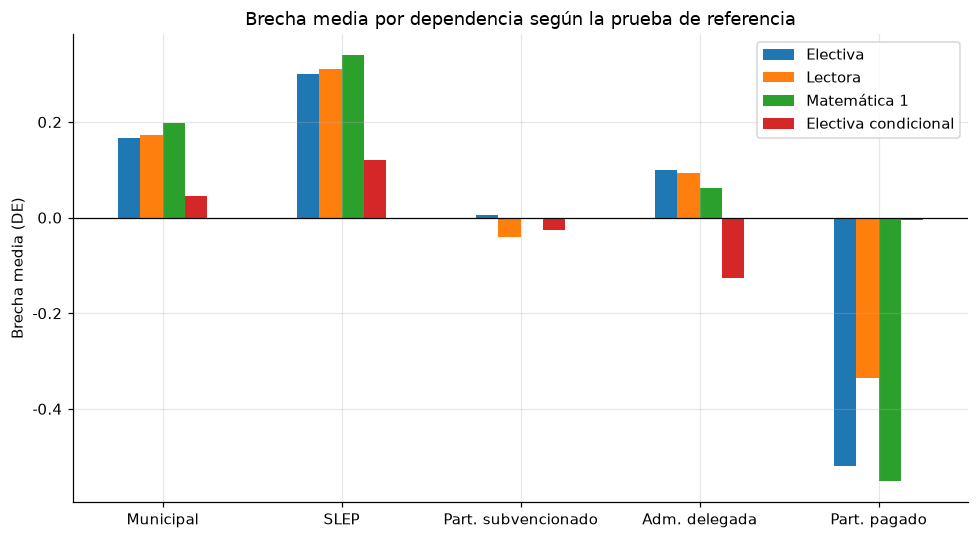

In [10]:
# 3.b ¿Las tres brechas ordenan igual a los grupos de dependencia?
versiones = {'brecha': 'Electiva', 'brecha_CLEC': 'Lectora',
             'brecha_MATE1': 'Matemática 1',
             'brecha_cond': 'Electiva condicional'}
print('Correlación entre versiones de la brecha (nivel estudiante):')
display(muestra[list(versiones)].corr().round(3))

medias = (muestra.groupby('dependencia', observed=True)[list(versiones)]
          .mean().rename(columns=versiones))
display(medias.round(3))

ax = medias.plot(kind='bar', rot=0)
ax.axhline(0, color='black', linewidth=0.8)
ax.set(title='Brecha media por dependencia según la prueba de referencia',
       xlabel='', ylabel='Brecha media (DE)')
plt.tight_layout()
mostrar('eda_3b')

## 4 Pregunta 1: ¿cómo se relacionan el NEM y la PAES?

In [11]:
# 4.a Descriptivos de notas, NEM y PAES electiva por año y electiva.
descriptivos = muestra.groupby(['ANIO', 'electiva'])[
    ['PROMEDIO_NOTAS', 'PTJE_NEM', 'PAES_electiva']
].describe(percentiles=[0.25, 0.5, 0.75])
# Se muestran solo media, DE y cuartiles para no saturar la salida.
cols = [(v, e) for v in ['PROMEDIO_NOTAS', 'PTJE_NEM', 'PAES_electiva']
        for e in ['mean', 'std', '25%', '50%', '75%']]
display(descriptivos[cols].round(2))

PROMEDIO_NOTAS                         PTJE_NEM                 \
                        mean   std   25%   50%   75%     mean     std    25%   
ANIO electiva                                                                  
2023 Ambas              6.06  0.49  5.70  6.10  6.45   730.35  140.04  630.0   
     Ciencias           6.08  0.50  5.70  6.10  6.48   734.86  144.41  628.0   
     Historia           5.95  0.49  5.58  5.98  6.33   699.58  141.66  595.0   
2024 Ambas              6.07  0.49  5.73  6.10  6.45   733.31  141.36  636.0   
     Ciencias           6.11  0.51  5.73  6.15  6.53   744.62  145.34  637.0   
     Historia           5.98  0.49  5.60  6.00  6.38   708.30  142.56  601.0   
2025 Ambas              6.07  0.48  5.73  6.10  6.43   732.29  137.34  636.0   
     Ciencias           6.11  0.49  5.75  6.15  6.50   745.49  141.14  643.0   
     Historia           5.98  0.47  5.63  6.00  6.35   707.26  136.98  608.0   
2026 Ambas              6.10  0.48  5.75  6.13  6.48   740.65  136.93  643.0   
     Ciencias           6.13  0.49  5.78  6.18  6.53   751.82  140.21  650.0   
     Historia           6.00  0.47  5.65  6.03  6.35   712.94  135.60  613.0   

                            PAES_electiva                               
                 50%    75%          mean     std    25%    50%    75%  
ANIO electiva                                                           
2023 Ambas     742.0  842.0        486.55   87.07  422.5  469.0  532.5  
     Ciencias  743.0  851.0        509.63  101.34  431.0  493.0  565.0  
     Historia  708.0  808.0        505.21  128.62  400.0  480.0  587.0  
2024 Ambas     742.0  842.0        464.34   89.27  400.0  446.0  510.0  
     Ciencias  757.0  865.0        491.28  112.18  413.0  468.0  548.0  
     Historia  713.0  823.0        506.13  137.18  396.0  484.0  595.0  
2025 Ambas     742.0  837.0        460.88   96.32  392.0  439.0  510.5  
     Ciencias  757.0  856.0        491.45  122.58  406.0  465.0  558.0  
     Historia  713.0  814.0        519.37  149.46  395.0  492.0  614.0  
2026 Ambas     751.0  851.0        456.10   89.24  394.0  436.0  499.5  
     Ciencias  765.0  865.0        477.23  125.28  393.0  435.0  533.0  
     Historia  722.0  815.0        526.98  140.61  418.0  500.0  607.0

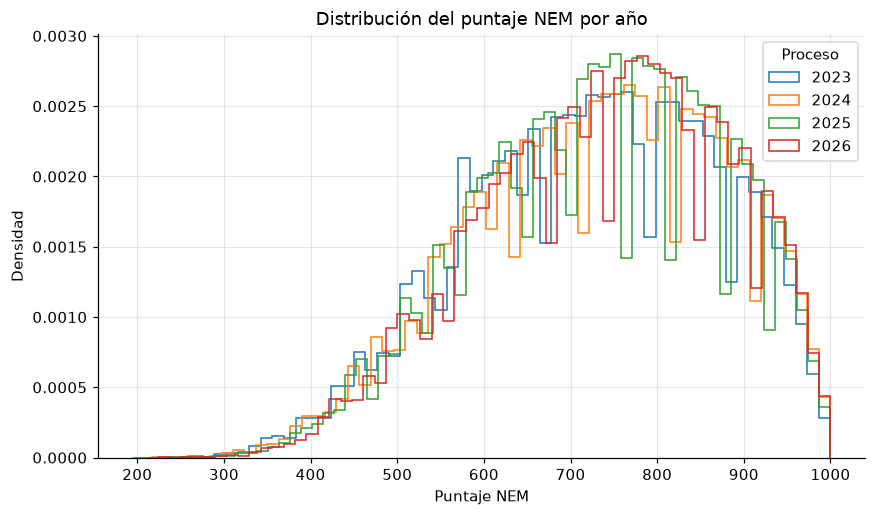

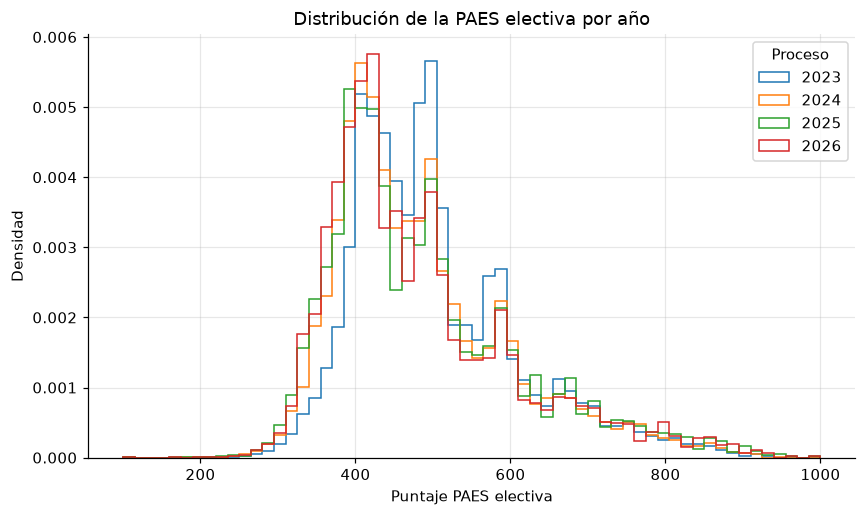

In [12]:
# 4.b Distribución de NEM y de la PAES electiva, una curva por año.
fig, ax = plt.subplots()
for anio, grupo in muestra.groupby('ANIO'):
    ax.hist(grupo['PTJE_NEM'], bins=60, histtype='step', density=True,
            label=str(anio))
ax.set(title='Distribución del puntaje NEM por año', xlabel='Puntaje NEM',
       ylabel='Densidad')
ax.legend(title='Proceso')
mostrar('eda_4b_nem')

fig, ax = plt.subplots()
for anio, grupo in muestra.groupby('ANIO'):
    ax.hist(grupo['PAES_electiva'], bins=60, histtype='step', density=True,
            label=str(anio))
ax.set(title='Distribución de la PAES electiva por año',
       xlabel='Puntaje PAES electiva', ylabel='Densidad')
ax.legend(title='Proceso')
mostrar('eda_4b_paes')

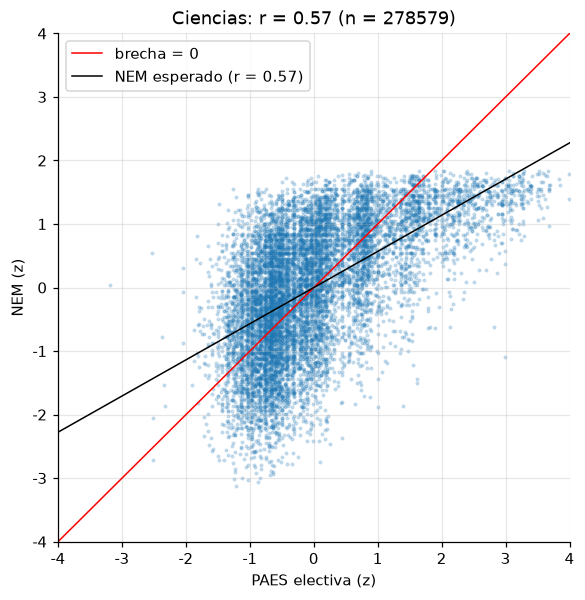

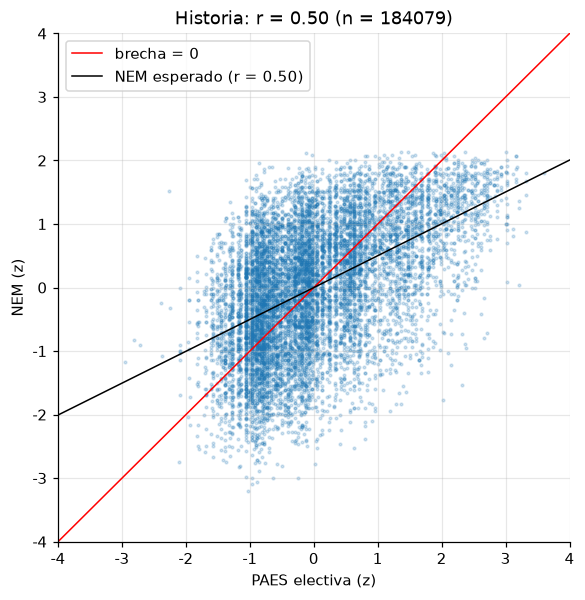

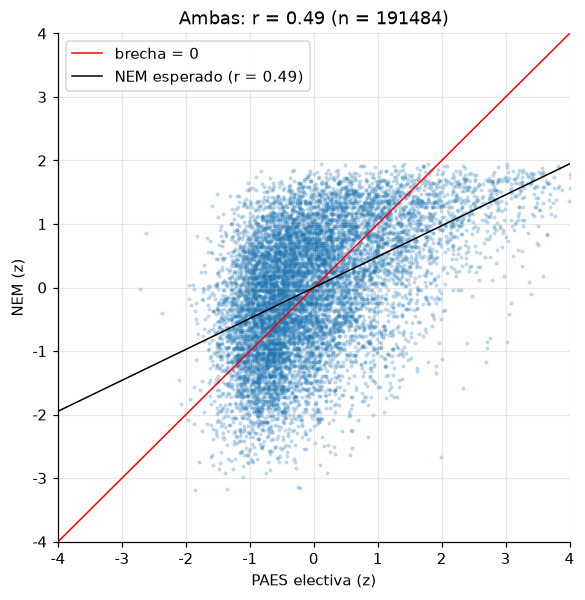

In [13]:
# 4.c NEM_z vs PAES_z, un gráfico por electiva (submuestra de 10 mil puntos
# para que se vea la nube). Sobre la diagonal roja la brecha simple es 0;
# bajo ella, brecha > 0. La línea negra es el NEM esperado dada la PAES
# (r * PAES_z): su menor pendiente es la regresión a la media.
for electiva in ELECTIVAS:
    datos = muestra[muestra['electiva'] == electiva]
    if len(datos) == 0:
        continue
    r = datos['NEM_z'].corr(datos['PAES_z'])
    sub = datos.sample(n=min(10_000, len(datos)), random_state=2026)

    fig, ax = plt.subplots(figsize=(6, 6))
    ax.scatter(sub['PAES_z'], sub['NEM_z'], s=3, alpha=0.2)
    ax.plot([-4, 4], [-4, 4], color='red', linewidth=1, label='brecha = 0')
    ax.plot([-4, 4], [-4 * r, 4 * r], color='black', linewidth=1,
            label=f'NEM esperado (r = {r:.2f})')
    ax.set(title=f'{electiva}: r = {r:.2f} (n = {len(datos)})',
           xlabel='PAES electiva (z)', ylabel='NEM (z)',
           xlim=(-4, 4), ylim=(-4, 4))
    ax.legend(loc='upper left')
    mostrar(f'eda_4c_{electiva.lower()}')

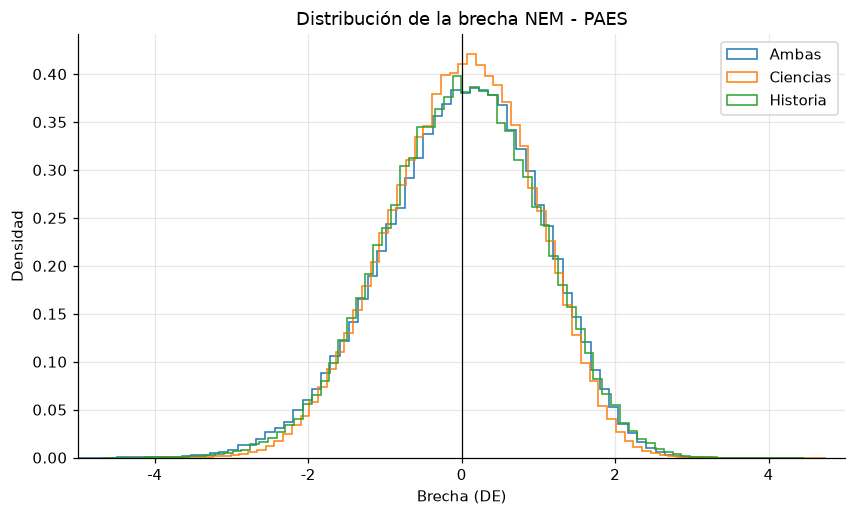

|brecha| > 1 DE: 31.2%
brecha > 1 DE:  15.6%
brecha < -1 DE: 15.7%


In [14]:
# 4.d Distribución de la brecha y proporción de casos con brechas grandes.
fig, ax = plt.subplots()
for electiva, grupo in muestra.groupby('electiva'):
    ax.hist(grupo['brecha'], bins=80, histtype='step', density=True,
            label=electiva)
ax.axvline(0, color='black', linewidth=0.8)
ax.set(title='Distribución de la brecha NEM - PAES',
       xlabel='Brecha (DE)', ylabel='Densidad', xlim=(-5, 5))
ax.legend()
mostrar('eda_4d')

print(f"|brecha| > 1 DE: {(muestra['brecha'].abs() > 1).mean():.1%}")
print(f"brecha > 1 DE:  {(muestra['brecha'] > 1).mean():.1%}")
print(f"brecha < -1 DE: {(muestra['brecha'] < -1).mean():.1%}")

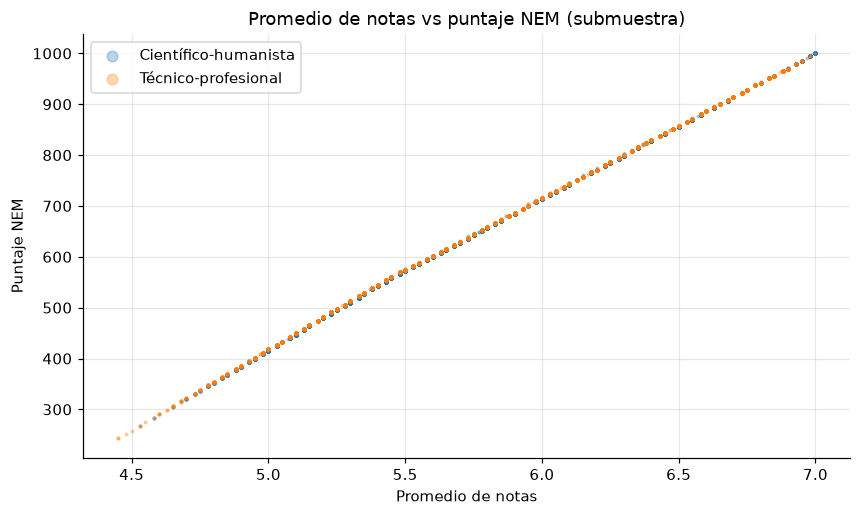

In [15]:
# 4.e Conversión de promedio de notas a puntaje NEM según modalidad.
# La tabla de conversión DEMRE depende de la modalidad (HC / TP), así que
# un mismo promedio puede dar distinto NEM. Si las nubes no coinciden,
# parte de la brecha por modalidad es un efecto de escala, no de notas.
sub = muestra.sample(n=min(30_000, len(muestra)), random_state=2026)
fig, ax = plt.subplots()
for modalidad, grupo in sub.groupby('modalidad'):
    ax.scatter(grupo['PROMEDIO_NOTAS'], grupo['PTJE_NEM'], s=3, alpha=0.3,
               label=modalidad)
ax.set(title='Promedio de notas vs puntaje NEM (submuestra)',
       xlabel='Promedio de notas', ylabel='Puntaje NEM')
ax.legend(markerscale=4)
mostrar('eda_4e')

## 5 Pregunta 2: brecha según dependencia y nivel socioeconómico

Desde esta sección, la **medida principal es la brecha condicional**
(`brecha_cond`): el NEM observado menos el NEM esperado para la PAES del estudiante.
La razón de esta elección se explica antes de 5.f, y 5.f compara ambas brechas.
Además de la brecha, se muestran sus componentes (NEM_z y PAES_z) para ver de dónde
viene cada diferencia.

Brecha condicional por dependencia:


,n,media,de,mediana,ic95_inf,ic95_sup
dependencia,,,,,,
Municipal,164087,0.045,0.890,0.101,0.041,0.049
SLEP,37375,0.120,0.881,0.181,0.111,0.129
Part. subvencionado,350115,-0.025,0.858,0.037,-0.028,-0.022
Adm. delegada,21187,-0.126,0.917,-0.090,-0.138,-0.114
Part. pagado,81378,-0.005,0.668,0.026,-0.010,-0.000


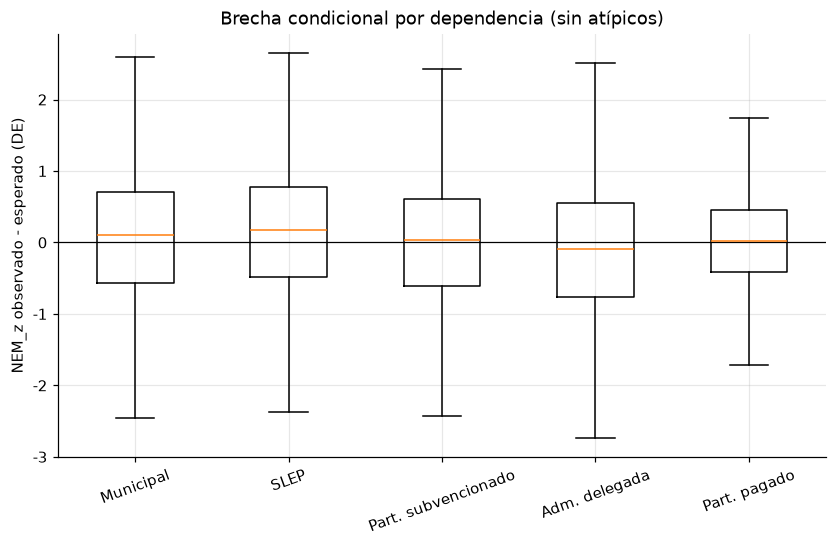

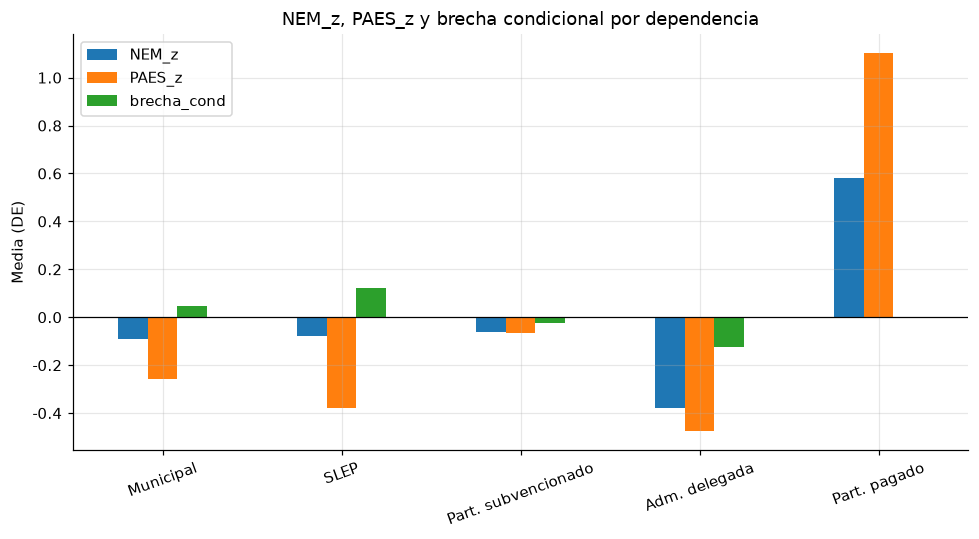

In [16]:
# 5.a Brecha condicional por dependencia: tabla, boxplot y componentes.
print('Brecha condicional por dependencia:')
display(resumen(muestra, 'dependencia', 'brecha_cond'))

# Boxplot: una caja por dependencia (sin atípicos para que se lea mejor).
etiquetas = [d for d in ORDEN_DEPENDENCIA
             if (muestra['dependencia'] == d).any()]
cajas = [muestra.loc[muestra['dependencia'] == d, 'brecha_cond']
         for d in etiquetas]
fig, ax = plt.subplots()
ax.boxplot(cajas, showfliers=False)
ax.set_xticks(range(1, len(etiquetas) + 1), etiquetas, rotation=20)
ax.axhline(0, color='black', linewidth=0.8)
ax.set(title='Brecha condicional por dependencia (sin atípicos)',
       ylabel='NEM_z observado - esperado (DE)')
mostrar('eda_5a_boxplot')

# Componentes: NEM_z, PAES_z y la brecha condicional (NEM_z menos el NEM
# esperado para esa PAES).
componentes = muestra.groupby('dependencia', observed=True)[
    ['NEM_z', 'PAES_z', 'brecha_cond']].mean()
ax = componentes.plot(kind='bar', rot=20)
ax.axhline(0, color='black', linewidth=0.8)
ax.set(title='NEM_z, PAES_z y brecha condicional por dependencia',
       xlabel='', ylabel='Media (DE)')
plt.tight_layout()
mostrar('eda_5a_componentes')

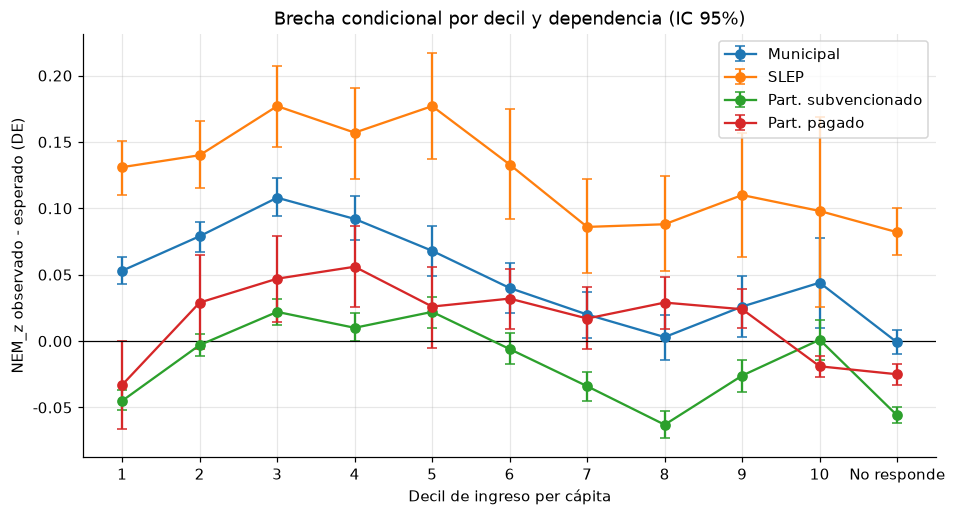

In [17]:
# 5.b Brecha condicional por decil de ingreso, una línea por dependencia.
# Permite ver si, a igual PAES, el NEM cambia con el nivel socioeconómico
# dentro de cada tipo de establecimiento. Se muestra el IC 95% porque las
# diferencias son pequeñas y así se ve cuáles se distinguen de 0.
fig, ax = plt.subplots(figsize=(10, 5))
for dependencia in ['Municipal', 'SLEP', 'Part. subvencionado',
                    'Part. pagado']:
    datos = muestra[muestra['dependencia'] == dependencia]
    graficar_medias(resumen(datos, 'decil', 'brecha_cond'), ax, dependencia)
ax.axhline(0, color='black', linewidth=0.8)
ax.set(title='Brecha condicional por decil y dependencia (IC 95%)',
       xlabel='Decil de ingreso per cápita',
       ylabel='NEM_z observado - esperado (DE)')
ax.legend()
mostrar('eda_5b')

In [18]:
# 5.c Tabla dependencia x decil con la brecha condicional media (se ocultan
# las celdas con menos de MIN_N_CELDA estudiantes). El color ayuda a
# leerla: rojo = brecha positiva, azul = negativa. Se guarda como CSV en
# imgs/ para usarla en el informe.
tabla_media = muestra.pivot_table(index='dependencia', columns='decil',
                                  values='brecha_cond', aggfunc='mean',
                                  observed=True)
tabla_n = muestra.pivot_table(index='dependencia', columns='decil',
                              values='brecha_cond', aggfunc='count',
                              observed=True)
tabla_media = tabla_media.where(tabla_n >= MIN_N_CELDA).round(3)

limite = tabla_media.abs().max().max()
display(tabla_media.style
        .background_gradient(cmap='RdBu_r', vmin=-limite, vmax=limite,
                             axis=None)
        .format('{:.2f}', na_rep=''))

ruta_csv = DIR_IMGS / 'eda_5c_brecha_cond_dependencia_decil.csv'
tabla_media.to_csv(ruta_csv, sep=';', decimal=',')
print(f'Tabla guardada en imgs/{ruta_csv.name}')

decil,1,2,3,4,5,6,7,8,9,10,No responde
dependencia,,,,,,,,,,,
Municipal,0.05,0.08,0.11,0.09,0.07,0.04,0.02,0.00,0.03,0.04,-0.00
SLEP,0.13,0.14,0.18,0.16,0.18,0.13,0.09,0.09,0.11,0.10,0.08
Part. subvencionado,-0.04,-0.00,0.02,0.01,0.02,-0.01,-0.03,-0.06,-0.03,0.00,-0.06
Adm. delegada,-0.16,-0.10,-0.09,-0.07,-0.10,-0.13,-0.13,-0.20,-0.14,-0.03,-0.12
Part. pagado,-0.03,0.03,0.05,0.06,0.03,0.03,0.02,0.03,0.02,-0.02,-0.03


Tabla guardada en imgs/eda_5c_brecha_cond_dependencia_decil.csv


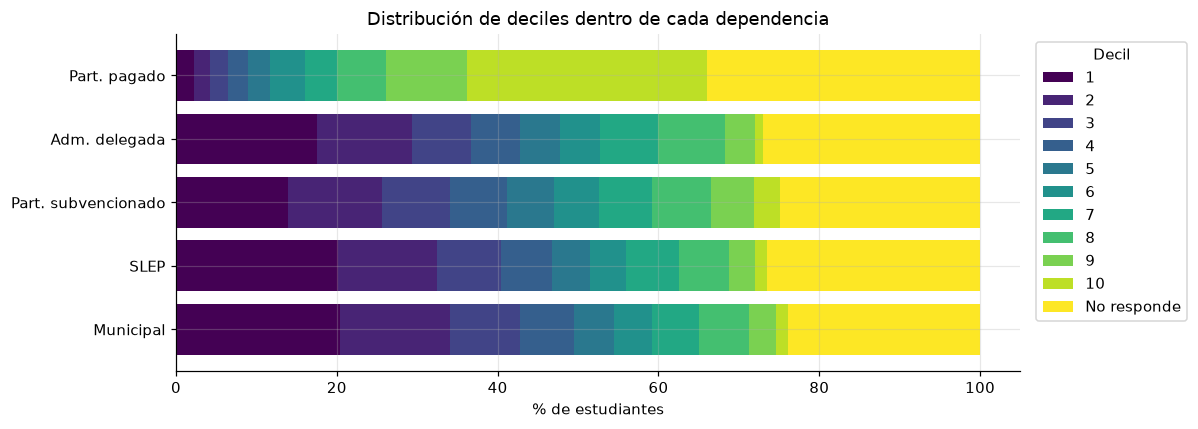

V de Cramér dependencia x decil (sin no respuesta): 0.265


In [19]:
# 5.d Composición socioeconómica de cada dependencia: anticipa la
# colinealidad que luego medirá el VIF.
composicion = pd.crosstab(muestra['dependencia'], muestra['decil'],
                          normalize='index')
ax = (100 * composicion).plot(kind='barh', stacked=True, figsize=(11, 4),
                              colormap='viridis', width=0.8)
ax.set(title='Distribución de deciles dentro de cada dependencia',
       xlabel='% de estudiantes', ylabel='')
ax.legend(title='Decil', bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout()
mostrar('eda_5d')

declaran = muestra[muestra['decil'] != 'No responde']
v = v_de_cramer(pd.crosstab(declaran['dependencia'],
                            declaran['decil'].astype(str)))
print(f'V de Cramér dependencia x decil (sin no respuesta): {v:.3f}')

In [20]:
# 5.e Brecha condicional según modalidad y sexo (posibles variables de
# control).
for variable in ['modalidad', 'sexo']:
    print(f'\nBrecha condicional por {variable}:')
    display(resumen(muestra, variable, 'brecha_cond'))


Brecha condicional por modalidad:


,n,media,de,mediana,ic95_inf,ic95_sup
modalidad,,,,,,
Científico-humanista,487681,0.018,0.828,0.076,0.015,0.020
Técnico-profesional,166461,-0.052,0.907,-0.019,-0.056,-0.047



Brecha condicional por sexo:


,n,media,de,mediana,ic95_inf,ic95_sup
sexo,,,,,,
Hombre,305973,-0.201,0.841,-0.161,-0.204,-0.198
Mujer,348169,0.177,0.817,0.245,0.174,0.180


### ¿Por qué la brecha condicional es la medida principal?

**Regresión a la media.** El NEM y la PAES están relacionados, pero no de forma
perfecta (su correlación es cercana a 0,5). Cuando dos medidas se relacionan así,
quien tiene un valor muy alto en una suele tener un valor alto en la otra, pero
**menos extremo**. Es lo mismo que pasa con la estatura: los hijos de padres muy
altos suelen ser altos, pero en promedio menos que sus padres. No hay nada
"injusto" en eso; es lo que ocurre siempre que dos medidas no coinciden del todo.

**El problema de la brecha simple.** La brecha simple (`NEM_z - PAES_z`) resta las
dos posiciones directamente. Por la regresión a la media, cualquier grupo con PAES
alta tendrá en promedio una brecha simple negativa, y cualquier grupo con PAES baja
una positiva, **aunque el NEM funcione exactamente igual para todos**. La brecha
simple mezcla diferencias reales con este efecto estadístico.

**Ejemplo: Part. pagado.** Sus estudiantes tienen en promedio PAES_z = +1,11. Con una
correlación cercana a 0,5, el NEM esperado para *cualquier* estudiante con esa PAES
es cercano a +0,58, y el NEM real de Part. pagado es +0,58: justo el esperado. Aun
así, la brecha simple da 0,58 - 1,11 = **-0,53**, como si sus notas estuvieran
"desinfladas". La brecha condicional da **0,00**: a igual PAES, sus estudiantes
tienen el mismo NEM que el resto.

**Por qué responde mejor la pregunta.** La pregunta del proyecto es *"a igual PAES,
¿distinto NEM?"*. La brecha condicional responde exactamente eso: compara el NEM de
cada estudiante con el de otros estudiantes que obtuvieron la misma PAES. Además,
es la misma idea del modelo jerárquico propuesto (`NEM_z ~ PAES_z + ...`), así que
el EDA y el modelo miden lo mismo.

### 5.f Comparación entre la brecha simple y la brecha condicional

Esta sección muestra con los datos la diferencia entre ambas medidas: por
dependencia, modalidad y sexo (5.f.1), por decil (5.f.2, comparar con 5.b) y el
techo del NEM (5.f.3). El NEM tiene un techo (promedio 7,0 = 1000 puntos), visible
en 4.c, que limita el NEM de quienes tienen PAES alta.

Medias por dependencia (DE):


,n,NEM_z,PAES_z,brecha_simple,brecha_condicional
dependencia,,,,,
Municipal,164087,-0.090,-0.256,0.166,0.045
SLEP,37375,-0.078,-0.378,0.300,0.120
Part. subvencionado,350115,-0.062,-0.067,0.005,-0.025
Adm. delegada,21187,-0.377,-0.476,0.099,-0.126
Part. pagado,81378,0.582,1.103,-0.521,-0.005


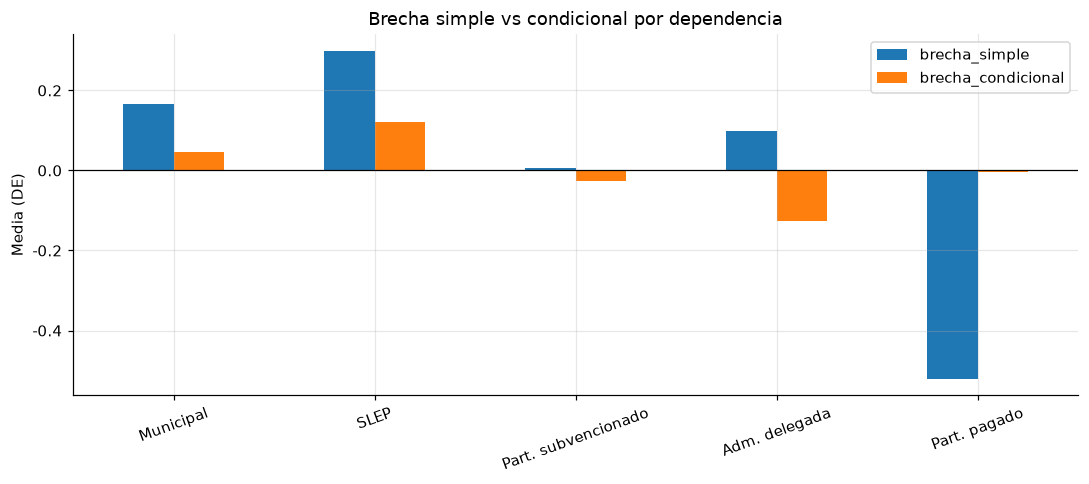


Medias por modalidad (DE):


,NEM_z,PAES_z,brecha,brecha_cond
modalidad,,,,
Científico-humanista,0.113,0.181,-0.068,0.018
Técnico-profesional,-0.331,-0.531,0.200,-0.052



Medias por sexo (DE):


,NEM_z,PAES_z,brecha,brecha_cond
sexo,,,,
Hombre,-0.160,0.077,-0.237,-0.201
Mujer,0.141,-0.068,0.208,0.177


In [21]:
# 5.f.1 Brecha simple vs condicional por dependencia.
comparacion = muestra.groupby('dependencia', observed=True).agg(
    n=('brecha', 'size'),
    NEM_z=('NEM_z', 'mean'),
    PAES_z=('PAES_z', 'mean'),
    brecha_simple=('brecha', 'mean'),
    brecha_condicional=('brecha_cond', 'mean'),
)
print('Medias por dependencia (DE):')
display(comparacion.round(3))

ax = comparacion[['brecha_simple', 'brecha_condicional']].plot(
    kind='bar', rot=20, figsize=(10, 4.5))
ax.axhline(0, color='black', linewidth=0.8)
ax.set(title='Brecha simple vs condicional por dependencia', xlabel='',
       ylabel='Media (DE)')
plt.tight_layout()
mostrar('eda_5f1')

# Lo mismo para modalidad y sexo.
for variable in ['modalidad', 'sexo']:
    print(f'\nMedias por {variable} (DE):')
    display(muestra.groupby(variable)[['NEM_z', 'PAES_z', 'brecha',
                                       'brecha_cond']].mean().round(3))

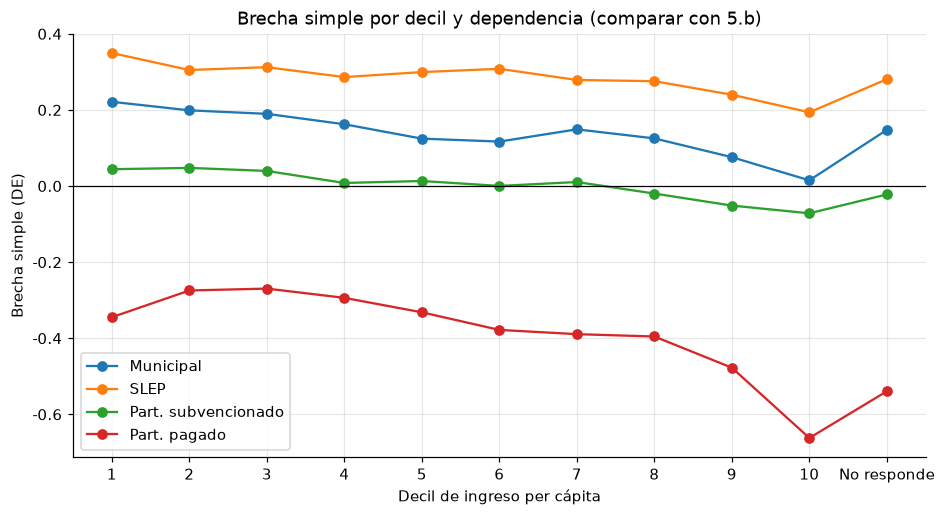

In [22]:
# 5.f.2 Brecha SIMPLE por decil, una línea por dependencia. Comparar con
# 5.b: el gradiente por decil que aparece aquí casi desaparece en la
# brecha condicional, porque viene de las diferencias de PAES.
fig, ax = plt.subplots(figsize=(10, 5))
for dependencia in ['Municipal', 'SLEP', 'Part. subvencionado',
                    'Part. pagado']:
    datos = muestra[muestra['dependencia'] == dependencia]
    medias = datos.groupby('decil', observed=True)['brecha'].mean()
    ax.plot(medias.index.astype(str), medias.values, marker='o',
            label=dependencia)
ax.axhline(0, color='black', linewidth=0.8)
ax.set(title='Brecha simple por decil y dependencia (comparar con 5.b)',
       xlabel='Decil de ingreso per cápita', ylabel='Brecha simple (DE)')
ax.legend()
mostrar('eda_5f2')

In [23]:
# 5.f.3 Techo del NEM: % de estudiantes con NEM máximo (promedio 7,0).
# Si un grupo concentra muchos casos en el techo, su brecha está acotada
# hacia arriba y conviene considerarlo al interpretar (o en el modelo).
NEM_MAXIMO: float = muestra['PTJE_NEM'].max()
muestra['nem_en_techo'] = muestra['PTJE_NEM'] >= NEM_MAXIMO
terciles = pd.qcut(muestra['PAES_z'], 3,
                   labels=['PAES baja', 'PAES media', 'PAES alta'])
techo = 100 * (muestra.groupby(['dependencia', terciles],
                               observed=True)['nem_en_techo'].mean()
               .unstack())
print(f'NEM máximo observado: {NEM_MAXIMO:.0f}')
print(f"% en el techo (total): {100 * muestra['nem_en_techo'].mean():.1f}%")
print('% en el techo por dependencia y tercil de PAES:')
display(techo.round(1))

NEM máximo observado: 1000
% en el techo (total): 0.2%
% en el techo por dependencia y tercil de PAES:


PAES_z,PAES baja,PAES media,PAES alta
dependencia,,,
Municipal,0.0,0.0,0.5
SLEP,0.0,0.1,0.6
Part. subvencionado,0.0,0.0,0.5
Adm. delegada,0.0,0.0,0.2
Part. pagado,0.0,0.0,0.9


## 6 Nivel establecimiento (insumo para el modelo jerárquico)

El modelo jerárquico tendrá estudiantes (nivel 1) dentro de establecimientos (nivel 2,
identificados por `RBD`). Esta sección mide qué parte de la variación ocurre *entre*
colegios con la **proporción de varianza entre colegios**: la varianza del promedio
de cada colegio dividida por la varianza total. Es una versión simple del
coeficiente de correlación intraclase (ICC), que lo sobreestima levemente; el ICC
exacto saldrá del modelo jerárquico. También se describen las variables candidatas
a nivel colegio: dependencia y composición socioeconómica. La medida principal es
la brecha condicional; la simple se muestra solo como referencia.

In [24]:
# 6.a Agregación por establecimiento (4 años juntos).
# Columna auxiliar: 1 si el estudiante es de los deciles 1 a 3, 0 si es de
# otro decil y NaN si no declara ingreso. Su promedio por colegio es la
# proporción de estudiantes de deciles 1 a 3 (entre quienes declaran).
muestra['decil_1a3'] = np.where(muestra['decil_num'].isna(), np.nan,
                                muestra['decil_num'] <= 3)
colegios = muestra.groupby('RBD').agg(
    n=('brecha_cond', 'size'),
    brecha_cond_media=('brecha_cond', 'mean'),
    brecha_simple_media=('brecha', 'mean'),
    nem_z_media=('NEM_z', 'mean'),
    paes_z_media=('PAES_z', 'mean'),
    decil_medio=('decil_num', 'mean'),
    pct_decil_1a3=('decil_1a3', 'mean'),
    n_dependencias=('DEPENDENCIA', 'nunique'),
)
# Dependencia del colegio: la del año más reciente en que aparece (si cambió,
# por ejemplo por un traspaso a SLEP, queda la administración actual).
ultima = (muestra.sort_values('ANIO')
          .drop_duplicates(subset='RBD', keep='last')
          .set_index('RBD')['dependencia'])
colegios['dependencia'] = ultima

print(f'Establecimientos en la muestra: {len(colegios)}')
print('Estudiantes por establecimiento:')
print(colegios['n'].describe().round(1).to_string())
print(f"Con al menos {MIN_ESTUDIANTES_COLEGIO} estudiantes: "
      f"{(colegios['n'] >= MIN_ESTUDIANTES_COLEGIO).sum()}")
# VERIFICAR: un RBD con más de una dependencia indica cambio de
# administración entre años (p. ej., traspaso a SLEP).
print(f"RBD con más de una dependencia: "
      f"{(colegios['n_dependencias'] > 1).sum()}")

Establecimientos en la muestra: 3034
Estudiantes por establecimiento:
count    3034.0
mean      215.6
std       180.0
min         1.0
25%        96.0
50%       171.0
75%       284.0
max      2136.0
Con al menos 10 estudiantes: 2980
RBD con más de una dependencia: 202


In [25]:
# 6.b Proporción de varianza entre colegios (src/estadistica.py), por año
# y con los 4 años juntos. Versión simple del ICC.
VARIABLES_COLEGIO: list[str] = ['brecha_cond', 'brecha', 'NEM_z', 'PAES_z']
prop_entre = pd.DataFrame(index=VARIABLES_COLEGIO)
for anio, grupo in muestra.groupby('ANIO'):
    prop_entre[anio] = [proporcion_varianza_entre(grupo, v, 'RBD')
                        for v in VARIABLES_COLEGIO]
prop_entre['4 años'] = [proporcion_varianza_entre(muestra, v, 'RBD')
                        for v in VARIABLES_COLEGIO]
print('Proporción de varianza entre colegios (fila: variable, '
      'columna: año):')
display(prop_entre.round(3))

Proporción de varianza entre colegios (fila: variable, columna: año):


,2023,2024,2025,2026,4 años
brecha_cond,0.165,0.174,0.172,0.174,0.136
brecha,0.196,0.215,0.250,0.277,0.206
NEM_z,0.224,0.218,0.175,0.159,0.164
PAES_z,0.337,0.341,0.337,0.353,0.329


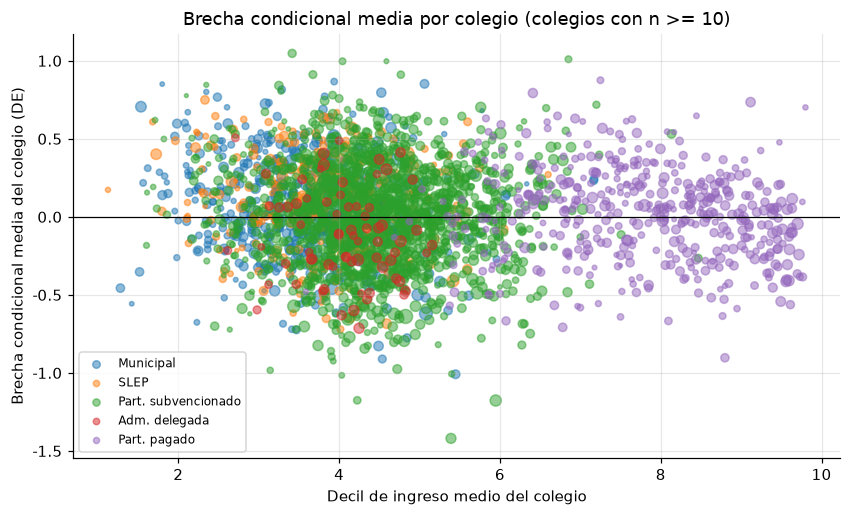

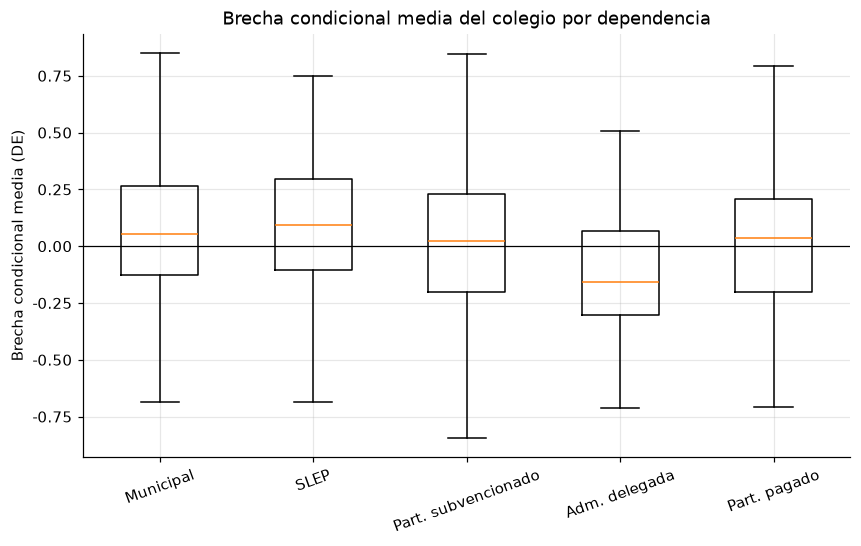

In [26]:
# 6.c Brecha condicional media por colegio vs nivel socioeconómico medio
# del colegio.
grandes = colegios[colegios['n'] >= MIN_ESTUDIANTES_COLEGIO]
fig, ax = plt.subplots(figsize=(9, 5))
for dependencia, grupo in grandes.groupby('dependencia', observed=True):
    ax.scatter(grupo['decil_medio'], grupo['brecha_cond_media'],
               s=np.sqrt(grupo['n']) * 2, alpha=0.5, label=dependencia)
ax.axhline(0, color='black', linewidth=0.8)
ax.set(title=f'Brecha condicional media por colegio (colegios con n >= '
             f'{MIN_ESTUDIANTES_COLEGIO})',
       xlabel='Decil de ingreso medio del colegio',
       ylabel='Brecha condicional media del colegio (DE)')
ax.legend(markerscale=0.7, fontsize=8)
mostrar('eda_6c_dispersion')

# Boxplot de la brecha condicional media de los colegios, por dependencia.
etiquetas = [d for d in ORDEN_DEPENDENCIA
             if (grandes['dependencia'] == d).any()]
cajas = [grandes.loc[grandes['dependencia'] == d, 'brecha_cond_media']
         for d in etiquetas]
fig, ax = plt.subplots()
ax.boxplot(cajas, showfliers=False)
ax.set_xticks(range(1, len(etiquetas) + 1), etiquetas, rotation=20)
ax.axhline(0, color='black', linewidth=0.8)
ax.set(title='Brecha condicional media del colegio por dependencia',
       ylabel='Brecha condicional media (DE)')
mostrar('eda_6c_boxplot')

## 7 Pregunta 3: brecha y etapas del acceso

Siguiendo la retroalimentación, el acceso se separa en etapas: **postuló** (aparece en
PS), **postulación válida** (seleccionado o lista de espera en alguna
preferencia), **seleccionado** (estado 24 o 26 en alguna preferencia) y
**matriculado** (aparece en M). Las tasas se muestran sobre toda la muestra y
condicionadas a la etapa anterior.

Advertencia de interpretación: NEM y PAES entran directamente al puntaje ponderado,
así que parte de cualquier asociación brecha-acceso es mecánica. La celda 7.c
compara estudiantes con PAES similar (terciles de PAES) y usa la brecha
condicional, que ya descuenta el NEM esperado para cada PAES.

In [27]:
# 7.a Tasas por etapa según dependencia y decil (src/estadistica.py).
print(f'Códigos usados -> seleccionado: {sorted(ESTADOS_SELECCION)}, '
      f'válida (seleccionado o espera): {sorted(ESTADOS_VALIDOS)}')
for grupo in ['dependencia', 'decil']:
    print(f'\nTasas de acceso (%) por {grupo}:')
    display(tasas_acceso(muestra, grupo))

Códigos usados -> seleccionado: [24, 26], válida (seleccionado o espera): [24, 25, 26]

Tasas de acceso (%) por dependencia:


,n,postuló,válida,seleccionado,matriculado,matric. | seleccionado,matric. | postuló
dependencia,,,,,,,
Municipal,164087,61.6,58.1,48.7,41.8,79.2,65.7
SLEP,37375,59.6,55.4,47.4,42.5,81.4,68.5
Part. subvencionado,350115,67.3,65.0,54.4,45.4,77.9,65.6
Adm. delegada,21187,48.0,44.7,37.2,31.5,75.1,61.2
Part. pagado,81378,86.3,85.9,78.5,68.6,83.6,78.1



Tasas de acceso (%) por decil:


,n,postuló,válida,seleccionado,matriculado,matric. | seleccionado,matric. | postuló
decil,,,,,,,
1,95405,63.4,59.8,49.2,42.3,78.9,64.5
2,72012,66.3,63.4,52.8,44.9,79.0,65.8
3,50302,67.8,65.3,55.2,47.0,79.7,67.5
4,41755,68.9,66.5,56.6,47.7,79.1,67.5
5,33486,68.7,66.5,56.7,47.6,78.7,67.5
6,33642,67.9,65.4,55.8,47.0,78.9,67.5
7,39877,65.3,62.7,53.1,44.5,78.0,66.2
8,44945,65.9,63.4,53.6,44.8,77.9,66.0
9,34524,71.3,69.5,60.7,50.9,79.0,69.7


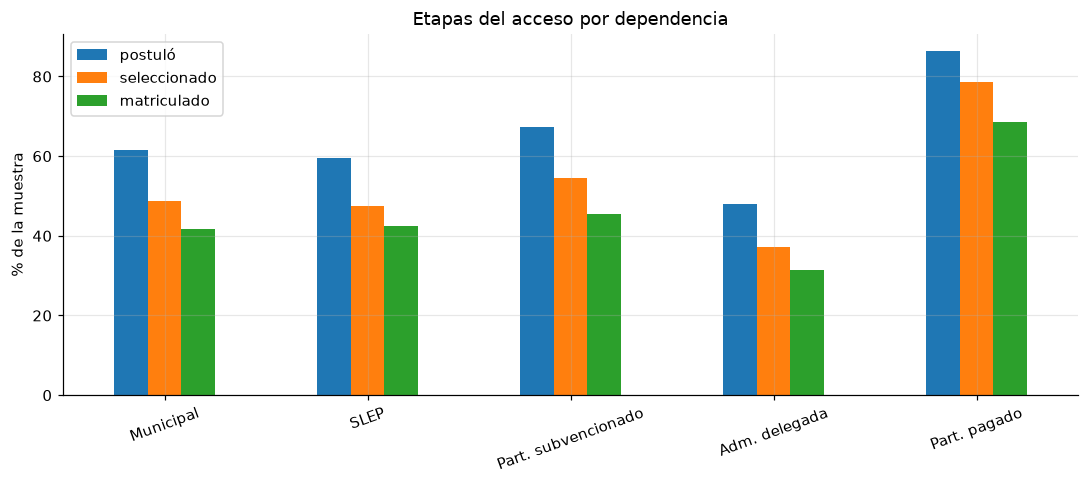

In [28]:
# 7.b Embudo de acceso por dependencia.
etapas = tasas_acceso(muestra, 'dependencia')[
    ['postuló', 'seleccionado', 'matriculado']]
ax = etapas.plot(kind='bar', rot=20, figsize=(10, 4.5))
ax.set(title='Etapas del acceso por dependencia', xlabel='',
       ylabel='% de la muestra')
plt.tight_layout()
mostrar('eda_7b')

% matriculado (toda la muestra):


tercil_paes,PAES baja,PAES media,PAES alta
quintil_brecha,,,
Q1,10.9,28.1,59.7
Q2,17.6,39.4,69.9
Q3,23.9,46.9,71.4
Q4,31.7,53.5,70.9
Q5,45.4,61.0,70.9


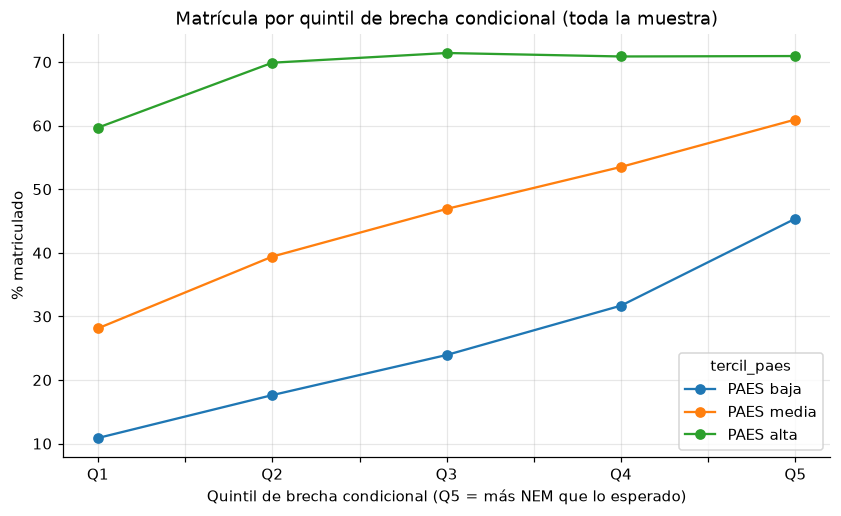

% matriculado (solo quienes postularon):


tercil_paes,PAES baja,PAES media,PAES alta
quintil_brecha,,,
Q1,32.2,50.1,74.2
Q2,39.8,59.4,79.1
Q3,47.3,65.7,79.3
Q4,55.2,70.3,78.4
Q5,68.6,75.8,79.2


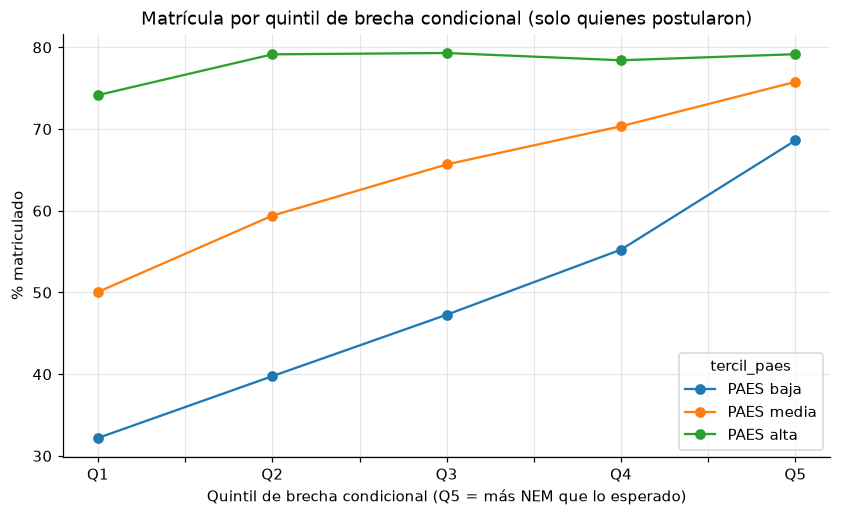

In [29]:
# 7.c Matrícula según quintil de brecha condicional, dentro de terciles de
# PAES_z. Si la tasa varía con la brecha incluso entre estudiantes con PAES
# similar, la asociación no se explica solo por el nivel de PAES.
muestra['quintil_brecha'] = pd.qcut(muestra['brecha_cond'], 5,
                                    labels=['Q1', 'Q2', 'Q3', 'Q4', 'Q5'])
muestra['tercil_paes'] = pd.qcut(muestra['PAES_z'], 3,
                                 labels=['PAES baja', 'PAES media',
                                         'PAES alta'])

versiones_7c = {
    'muestra': ('toda la muestra', muestra),
    'postulantes': ('solo quienes postularon', muestra[muestra['postulo']]),
}
for nombre, (titulo, datos) in versiones_7c.items():
    tasas = datos.pivot_table(index='quintil_brecha', columns='tercil_paes',
                              values='matriculado', aggfunc='mean',
                              observed=True)
    print(f'% matriculado ({titulo}):')
    display((100 * tasas).round(1))
    ax = (100 * tasas).plot(marker='o')
    ax.set(title=f'Matrícula por quintil de brecha condicional ({titulo})',
           xlabel='Quintil de brecha condicional (Q5 = más NEM que lo '
                  'esperado)',
           ylabel='% matriculado')
    mostrar(f'eda_7c_{nombre}')

## 8 Evolución 2023-2026

Como la brecha está estandarizada por año, su promedio general es 0 en cada proceso;
lo que sí puede cambiar en el tiempo es la **diferencia entre grupos**. Ojo: por ser
relativa a cada año, si la brecha de un grupo baja puede ser porque el NEM de los
otros grupos sube más, no porque el de ese grupo baje. Para mirar niveles absolutos
se usan las variables sin estandarizar (promedio de notas, % con promedio de 6,0 o
más, NEM, PAES). Con cuatro años, esto describe brechas observadas en el periodo, no
una tendencia de largo plazo de inflación de notas (pregunta 6 de la
retroalimentación).

In [30]:
# 8.a Niveles absolutos por año (variables sin estandarizar).
muestra['promedio_6_o_mas'] = muestra['PROMEDIO_NOTAS'] >= 6.0
niveles = muestra.groupby('ANIO').agg(
    promedio_notas=('PROMEDIO_NOTAS', 'mean'),
    pct_promedio_6=('promedio_6_o_mas', 'mean'),
    nem=('PTJE_NEM', 'mean'),
    lectora=('CLEC_1ra', 'mean'),
    m1=('MATE1_1ra', 'mean'),
)
niveles['pct_promedio_6'] *= 100
print('Medias anuales en la muestra (sin estandarizar):')
display(niveles.round(2))
print('Media de PAES electiva por año y electiva:')
display(muestra.pivot_table(index='ANIO', columns='electiva',
                            values='PAES_electiva', aggfunc='mean').round(1))

# % con promedio >= 6,0 por dependencia y año, y cambio 2023-2026 (en
# puntos porcentuales). Sirve para leer la evolución de la brecha
# condicional por dependencia (8.b), que es relativa a cada año.
pct_6 = 100 * muestra.pivot_table(index='dependencia', columns='ANIO',
                                  values='promedio_6_o_mas',
                                  aggfunc='mean', observed=True)
pct_6['cambio 2023-2026'] = pct_6[2026] - pct_6[2023]
print('% con promedio de notas >= 6,0 por dependencia y año:')
display(pct_6.round(1))
print('Brecha condicional media por dependencia y año:')
display(muestra.pivot_table(index='dependencia', columns='ANIO',
                            values='brecha_cond', aggfunc='mean',
                            observed=True).round(3))

Medias anuales en la muestra (sin estandarizar):


,promedio_notas,pct_promedio_6,nem,lectora,m1
ANIO,,,,,
2023,6.03,54.93,723.01,640.15,560.81
2024,6.06,56.96,730.74,595.45,602.40
2025,6.06,57.17,731.19,592.49,624.71
2026,6.09,59.22,738.00,607.09,632.22


Media de PAES electiva por año y electiva:


electiva,Ambas,Ciencias,Historia
ANIO,,,
2023,486.5,509.6,505.2
2024,464.3,491.3,506.1
2025,460.9,491.4,519.4
2026,456.1,477.2,527.0


% con promedio de notas >= 6,0 por dependencia y año:


ANIO,2023,2024,2025,2026,cambio 2023-2026
dependencia,,,,,
Municipal,51.3,52.3,53.8,56.8,5.5
SLEP,51.1,51.3,54.5,57.1,6.1
Part. subvencionado,52.3,55.1,54.8,56.3,4.0
Adm. delegada,35.6,38.8,43.1,49.9,14.3
Part. pagado,81.1,82.2,79.2,79.0,-2.1


Brecha condicional media por dependencia y año:


ANIO,2023,2024,2025,2026
dependencia,,,,
Municipal,0.030,0.022,0.056,0.079
SLEP,0.119,0.076,0.140,0.128
Part. subvencionado,-0.029,-0.014,-0.024,-0.033
Adm. delegada,-0.215,-0.194,-0.105,0.012
Part. pagado,0.083,0.041,-0.041,-0.092


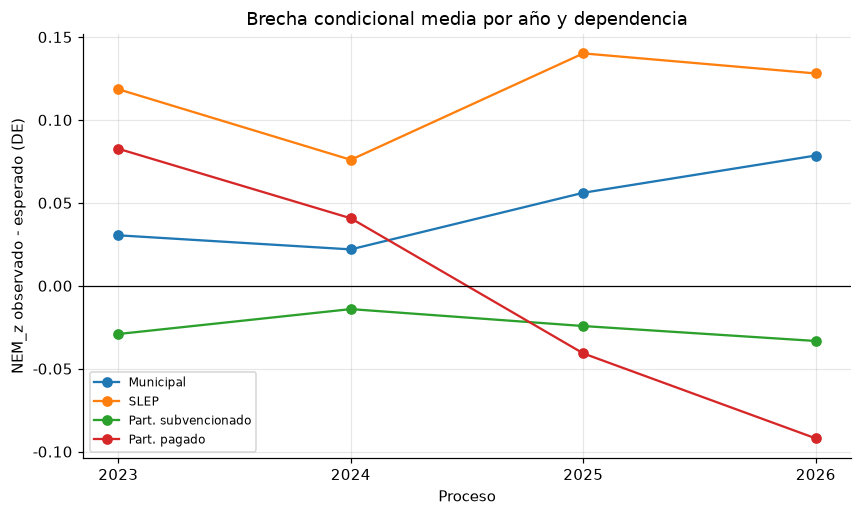

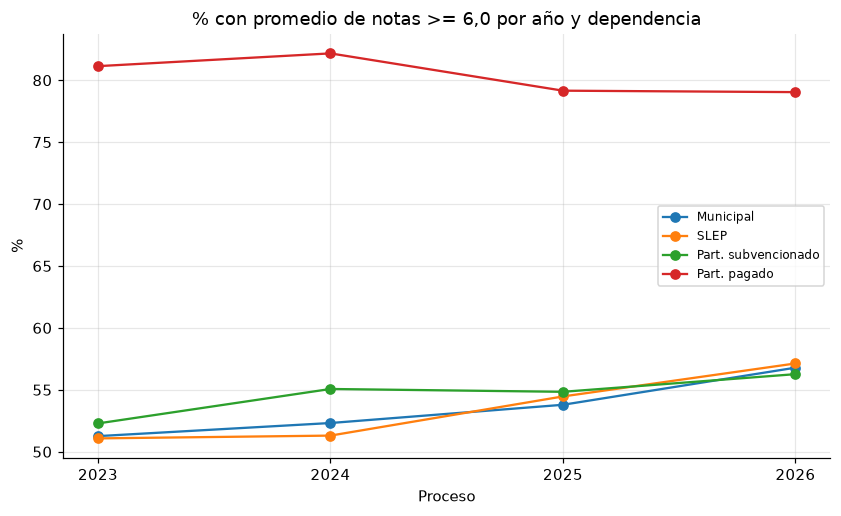

In [31]:
# 8.b Diferencias entre dependencias a lo largo del tiempo.
DEPENDENCIAS_8B: list[str] = ['Municipal', 'SLEP', 'Part. subvencionado',
                              'Part. pagado']

fig, ax = plt.subplots()
for dependencia in DEPENDENCIAS_8B:
    datos = muestra[muestra['dependencia'] == dependencia]
    medias = datos.groupby('ANIO')['brecha_cond'].mean()
    ax.plot(medias.index.astype(str), medias.values, marker='o',
            label=dependencia)
ax.axhline(0, color='black', linewidth=0.8)
ax.set(title='Brecha condicional media por año y dependencia',
       xlabel='Proceso', ylabel='NEM_z observado - esperado (DE)')
ax.legend(fontsize=8)
mostrar('eda_8b_brecha')

fig, ax = plt.subplots()
for dependencia in DEPENDENCIAS_8B:
    datos = muestra[muestra['dependencia'] == dependencia]
    pct = 100 * datos.groupby('ANIO')['promedio_6_o_mas'].mean()
    ax.plot(pct.index.astype(str), pct.values, marker='o',
            label=dependencia)
ax.set(title='% con promedio de notas >= 6,0 por año y dependencia',
       xlabel='Proceso', ylabel='%')
ax.legend(fontsize=8)
mostrar('eda_8b_promedio6')

## Guardar la muestra para el modelamiento

In [32]:
# Guarda la muestra con brechas y variables (data/processed/ en .gitignore).
muestra.to_parquet(ARCHIVO_MUESTRA, index=False)
print(f'Guardado {ARCHIVO_MUESTRA.name}: {len(muestra)} filas, '
      f'{muestra.shape[1]} columnas')

Guardado muestra.parquet: 654142 filas, 49 columnas


## 9 Síntesis de hallazgos del EDA

Ejecución definitiva del 9 de octubre de 2026: grupo "Ambas" incluido, solo
educación regular en establecimientos identificados y **brecha condicional como
medida principal** (decisiones del equipo). Todos los resultados son descriptivos:
muestran asociaciones, no relaciones causales. Las brechas se miden en desviaciones
estándar (DE) dentro de cada año y grupo de electiva.

**Calidad y muestra.**

- Panel de 1.240.008 inscritos en cuatro procesos. La muestra analítica tiene
  **654.142 estudiantes**: 278.579 solo Ciencias, 191.484 Ambas y 184.079 solo
  Historia. El filtro que más elimina es el de egreso reciente (unos 405 mil
  inscritos de promociones anteriores); luego, no rendir ninguna electiva (unos
  136 mil) y no venir de la educación regular en un establecimiento identificado
  (27.791).
- **Educación regular en establecimiento identificado:** se excluye a quienes
  validan o reconocen estudios (H3 y H4, sin RBD ni dependencia: 2.250), a la
  educación de adultos (`CODIGO_ENS` x60 a x63 y 963: 25.529) y al RBD 99999 (12).
  Su NEM no proviene de un colegio regular comparable. Con esto desaparece el grupo
  "Sin dato" de dependencia.
- Códigos confirmados con los libros de códigos 2026 (`docs/`): `ESTADO_PREF` 24, 25
  y 26, `DEPENDENCIA` 1 a 6 y sexo 1 Hombre, 2 Mujer (el `SEXO` de SD coincide en
  el 100% de los casos con `COD_SEXO` de IP y con `SEXO` de PS). El RBD 99999 no
  aparece en los libros: sigue pendiente.
- **Seleccionado** = algún estado 24 o 26; **postulación válida** = 24, 25 o 26. Con
  esta definición, `postulacion_valida` coincide en el **100%** con
  `SITUACION_POSTULANTE = P` (control posible solo en 2023). El cambio solo afecta a
  2023, donde a algunos estudiantes con estado 26 les falta el registro del 24.
- Un 0 en un puntaje PAES significa "no rindió" (entre 13% y 54% según la prueba)
  y se trata como faltante. Casi nadie rinde en invierno ni en el proceso anterior
  (a lo más 51 casos por prueba y año).
- El 25,9% de la muestra no declara ingreso; se mantiene como categoría propia.
  Solo el 0,2% tiene el NEM máximo (1000 puntos).

**Pregunta 1: relación entre NEM y PAES.**

- La correlación NEM-PAES es moderada y estable entre años: entre 0,56 y 0,58 con
  Ciencias, entre 0,49 y 0,51 con Historia, entre 0,48 y 0,49 en el grupo Ambas,
  entre 0,53 y 0,56 con Lectora y entre 0,49 y 0,54 con Matemática 1. Como es
  cercana a 0,5 y no a 1, hay una regresión a la media importante: por eso se usa la
  brecha condicional.
- La conversión de notas a puntaje NEM es la misma en las modalidades
  científico-humanista y técnico-profesional (4.e).
- Las tres pruebas de referencia (electiva, Lectora y Matemática 1) ordenan igual a
  las dependencias; la elección de la electiva no cambia las conclusiones.

**Pregunta 2: dependencia y nivel socioeconómico.**

| Dependencia | n | NEM_z | PAES_z | Brecha condicional | Brecha simple |
|---|---:|---:|---:|---:|---:|
| Municipal | 164.087 | -0,090 | -0,256 | 0,045 | 0,166 |
| SLEP | 37.375 | -0,078 | -0,378 | 0,120 | 0,300 |
| Part. subvencionado | 350.115 | -0,062 | -0,067 | -0,025 | 0,005 |
| Adm. delegada | 21.187 | -0,377 | -0,476 | -0,126 | 0,099 |
| Part. pagado | 81.378 | 0,582 | 1,103 | -0,005 | -0,521 |

- **A igual PAES, las dependencias tienen un NEM muy parecido:** la brecha
  condicional queda entre -0,13 y +0,12. Las grandes diferencias de la brecha simple
  (de -0,52 a +0,30) vienen de la PAES, no del NEM (5.f).
- **SLEP** es la excepción más consistente: a igual PAES, sus estudiantes tienen un
  NEM entre 0,08 y 0,18 DE mayor, en todos los deciles de ingreso y en los tres
  grupos de electiva (entre 0,11 y 0,13). Adm. delegada está en el otro extremo
  (-0,13).
- **Decil de ingreso:** la brecha condicional casi no cambia con el decil (entre
  -0,04 y +0,05). El fuerte gradiente de la brecha simple (+0,12 en el decil 1 y
  -0,43 en el decil 10) se explica por la PAES.
- **Sexo:** es la diferencia más grande: mujeres +0,18 y hombres -0,20 en la
  brecha condicional. A igual PAES, las mujeres tienen un NEM 0,38 DE mayor.
- **Modalidad:** técnico-profesional -0,05 y científico-humanista +0,02 en la
  brecha condicional. La diferencia de la brecha simple (+0,20 frente a -0,07) era
  casi toda regresión a la media.
- Asociación dependencia x decil: V de Cramér = 0,265 (moderada), lo que anticipa
  colinealidad entre ambas variables en los modelos.

**Nivel colegio.**

- 3.034 establecimientos, con una mediana de 171 estudiantes en los cuatro años;
  2.980 tienen al menos 10. 202 colegios cambian de dependencia en el periodo
  (principalmente traspasos a SLEP).
- Proporción de varianza entre colegios de la brecha condicional: 0,14 con los
  cuatro años y cerca de 0,17 en cada año (estable). Como referencia: NEM_z 0,16;
  PAES_z 0,33; brecha simple 0,21 (sube de 0,20 a 0,28 entre años, porque la PAES se
  diferencia cada vez más entre colegios).
- Que entre 14% y 17% de la variación de la brecha condicional ocurra entre colegios
  justifica el modelo jerárquico con efecto aleatorio por colegio. Dentro de cada
  dependencia, los colegios varían mucho más (6.c) que los promedios entre
  dependencias. El ICC exacto saldrá del modelo jerárquico.

**Pregunta 3: etapas del acceso.**

- Las diferencias entre dependencias están en **postular** (de 48% en Adm. delegada
  a 86% en Part. pagado) y **quedar seleccionado** (de 37% a 79%). Una vez
  seleccionados, la matrícula es parecida: entre 75% y 84%.
- Por decil, el decil 10 se separa del resto: 82% postula y 85% de los
  seleccionados se matricula, frente a entre 63% y 71% y entre 78% y 80% en los
  demás deciles.
- A igual tercil de PAES, una brecha condicional mayor se asocia a más matrícula,
  sobre todo con PAES baja (de 11% en el quintil 1 a 45% en el quintil 5; entre
  quienes postulan, de 32% a 69%). Con PAES alta la relación es más débil (de 60% a
  71%; entre quienes postulan, de 74% a 79%). Parte de esta asociación es mecánica:
  el NEM pondera en el puntaje de postulación.

**Evolución 2023-2026.**

- El promedio de notas sube de 6,03 a 6,09, el porcentaje con promedio de 6,0 o más
  de 54,9% a 59,2% y el NEM medio de 723 a 738. Los puntajes PAES sin estandarizar
  no son comparables entre años, así que cuatro procesos no permiten hablar de
  inflación de notas.
- La brecha condicional de **Part. pagado** baja de +0,08 en 2023 a -0,09 en 2026
  (en los tres grupos de electiva), la de Adm. delegada sube de -0,22 a +0,01 y la
  de Municipal de 0,03 a 0,08. En SLEP, la comparación entre años mezcla colegios
  distintos por los traspasos.

> **Nota de cautela sobre Part. pagado.** La brecha condicional es **relativa a cada
> año**: compara a cada estudiante con todos los que rindieron ese año. Por eso, su
> caída en Part. pagado puede reflejar que el NEM de los otros grupos sube más, y no
> que baje el de Part. pagado. Los niveles absolutos (8.a) apoyan esa lectura: entre
> 2023 y 2026, el % con promedio de 6,0 o más casi no cambia en Part. pagado (de
> 81,1% a 79,0%, -2,1 puntos), mientras sube en todas las demás dependencias
> (Part. subvencionado +4,0; Municipal +5,5; SLEP +6,1; Adm. delegada +14,3 puntos).
> Es decir, las demás dependencias se acercan a Part. pagado en notas, mientras su
> ventaja en la PAES se mantiene (PAES_z de 1,08 a 1,12). Con cuatro años, esto es
> una descripción del periodo, no una tendencia.

**Comparación con el informe de avance (3 de octubre).**

- El código simplificado reproduce exactamente las cifras del informe cuando se
  usa la misma muestra (por ejemplo, brecha simple de Part. pagado -0,492 y brecha
  condicional de SLEP 0,115).
- Los dos cambios de muestra (incluir al grupo Ambas y dejar solo la educación
  regular) mueven poco las cifras. Brecha condicional, informe frente a versión
  definitiva: SLEP 0,115 y 0,120; Municipal 0,031 y 0,045; Part. subvencionado
  -0,017 y -0,025; Adm. delegada -0,102 y -0,126; Part. pagado 0,008 y -0,005.
- Se confirman los hallazgos del informe: la regresión a la media explica la mayor
  parte de la brecha simple, SLEP es la excepción, la diferencia por sexo es
  grande y las diferencias de acceso están en postular y quedar seleccionado.
- Hallazgos nuevos: la diferencia por sexo se mantiene en la brecha condicional; el
  gradiente por decil y la diferencia por modalidad desaparecen; y la brecha
  condicional de Part. pagado baja en el periodo (ver la nota de cautela).
- La proporción de varianza entre colegios reemplaza al ICC por ANOVA del informe,
  así que esas cifras no son exactamente comparables (brecha condicional 0,14 frente
  a 0,13).
- Los seleccionados de 2023 pasan de 140.558 a 142.902 por la nueva definición
  (estado 24 o 26); los demás años no cambian.

**Decisiones que salen del EDA.**

- **Medida principal:** brecha condicional. La brecha simple se mantiene solo como
  comparación en 5.f.
- **Muestra:** egresados recientes, con NEM válido, al menos una electiva (grupo
  Ambas incluido) y educación regular en un establecimiento identificado.
- **Prueba de referencia:** electiva; **criterio de rendición:** regular.
- **Acceso:** seleccionado = estado 24 o 26; postulación válida = 24, 25 o 26.
- **Variables para el modelo:** nivel estudiante (PAES_z, decil, sexo, año) y nivel
  colegio (dependencia, modalidad, composición socioeconómica), con efecto
  aleatorio por RBD. Hay que controlar por sexo.